In [2]:
import pandas as pd

df = pd.read_csv("../data/creditcard.csv")

print(df.shape)
print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")

counts = df["Class"].value_counts()
print(counts)
print((counts / len(df) * 100).round(3))

print(df.groupby("Class")["Amount"].describe())

ModuleNotFoundError: No module named 'pandas'

In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 23.4 MB/s  0:00:00a 0:00:0136m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 30.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 31.8 MB/s  0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 30.3 MB/s  0:00:00 89.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 30.9 MB/s  0:00:01 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 28.6 MB/s  0:00:02 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 27.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 29.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 26.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 26.4 MB/s  0:00:10 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20/20 [imbalanced-learn]2m19/20 [imbalanced-learn]

[notice] A new rele

In [1]:
import pandas as pd

df = pd.read_csv("../data/creditcard.csv")

print(df.shape)
print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")

counts = df["Class"].value_counts()
print(counts)
print((counts / len(df) * 100).round(3))

print(df.groupby("Class")["Amount"].describe())

FileNotFoundError: [Errno 2] No such file or directory: '../data/creditcard.csv'

In [2]:
import os
print(os.getcwd())
print(os.listdir(".."))
print(os.listdir("../data") if os.path.exists("../data") else "no data folder")

/workspaces/credit-card-fraud-detection
['.codespaces', '.oryx', 'credit-card-fraud-detection']
no data folder


In [3]:
mkdir -p data

In [4]:
import pandas as pd

df = pd.read_csv("../data/creditcard.csv")

print(df.shape)
print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")

counts = df["Class"].value_counts()
print(counts)
print((counts / len(df) * 100).round(3))

print(df.groupby("Class")["Amount"].describe())

FileNotFoundError: [Errno 2] No such file or directory: '../data/creditcard.csv'

In [5]:
import os
print("Current folder:", os.getcwd())
print("Files here:", os.listdir("."))
print("Files one level up:", os.listdir(".."))

Current folder: /workspaces/credit-card-fraud-detection
Files here: ['README.md', 'requirements.txt', 'data', '01_eda.ipynb', '.gitignore', '.ipynb_checkpoints', 'outputs', '.git', 'LICENSE', 'notebooks']
Files one level up: ['.codespaces', '.oryx', 'credit-card-fraud-detection']


In [6]:
import glob
print(glob.glob("/workspaces/**/creditcard*", recursive=True))

['/workspaces/credit-card-fraud-detection/data/creditcard.csv']


In [7]:
import pandas as pd

df = pd.read_csv("/workspaces/credit-card-fraud-detection/data/creditcard.csv")

print(df.shape)
print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")

counts = df["Class"].value_counts()
print(counts)
print((counts / len(df) * 100).round(3))

print(df.groupby("Class")["Amount"].describe())

(284807, 31)
0 missing values
1081 duplicate rows
Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827
1     0.173
Name: count, dtype: float64
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


In [10]:
from pathlib import Path

path = Path("data/creditcard.csv")
if not path.exists():
    path = Path("../data/creditcard.csv")

df = pd.read_csv(path)

In [11]:
dups = df[df.duplicated(keep=False)]
print(dups["Class"].value_counts())
print("Fraud rows among duplicates removed:", df[df.duplicated()]["Class"].sum())

Class
0    1822
1      32
Name: count, dtype: int64
Fraud rows among duplicates removed: 19


In [12]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print(df["Class"].value_counts())

(283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


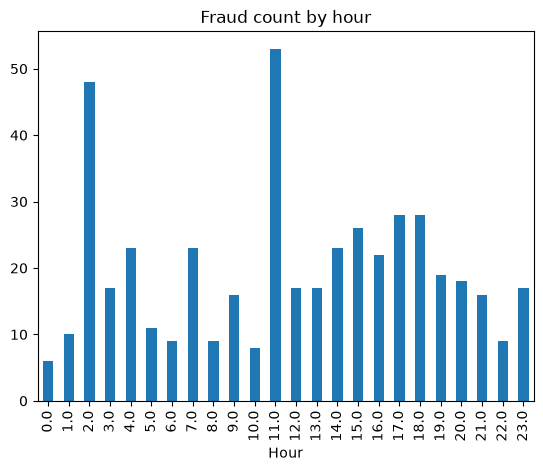

In [13]:
import matplotlib.pyplot as plt

df["Hour"] = (df["Time"] // 3600) % 24
df[df["Class"] == 1]["Hour"].value_counts().sort_index().plot(
    kind="bar", title="Fraud count by hour"
)
plt.show()

In [14]:
git add notebooks/01_eda.ipynb
git commit -m "Add EDA notebook with class imbalance analysis"
git push origin main

SyntaxError: invalid decimal literal (4015851637.py, line 1)

In [15]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	01_eda.ipynb

nothing added to commit but untracked files present (use "git add" to track)


In [17]:
from pathlib import Path
import pandas as pd

path = Path("data/creditcard.csv")
if not path.exists():
    path = Path("../data/creditcard.csv")

df = pd.read_csv(path)

In [18]:
# 1. Duplicate check
dups = df[df.duplicated(keep=False)]
print(dups["Class"].value_counts())
print("Fraud rows among duplicates removed:", df[df.duplicated()]["Class"].sum())

# 2. Drop duplicates
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print(df["Class"].value_counts())

Class
0    1822
1      32
Name: count, dtype: int64
Fraud rows among duplicates removed: 19
(283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


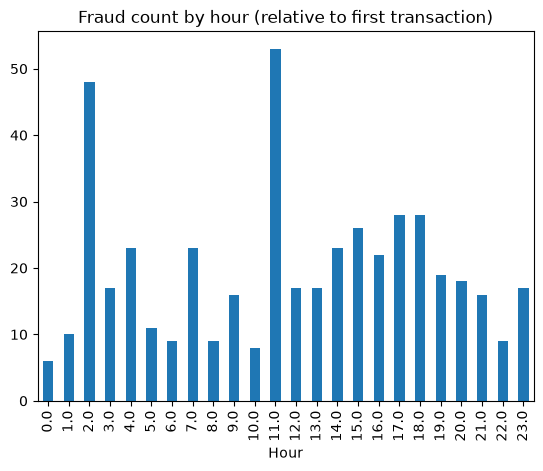

In [19]:
import matplotlib.pyplot as plt

df["Hour"] = (df["Time"] // 3600) % 24
df[df["Class"] == 1]["Hour"].value_counts().sort_index().plot(
    kind="bar", title="Fraud count by hour (relative to first transaction)"
)
plt.show()

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, average_precision_score

X = df.drop(columns=["Class", "Time", "Hour"], errors="ignore")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Scale Amount only (fit on train to avoid leakage)
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train["Amount"] = scaler.fit_transform(X_train[["Amount"]])
X_test["Amount"] = scaler.transform(X_test[["Amount"]])

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

pred = model.predict(X_test)
print(classification_report(y_test, pred, digits=3))
print("PR-AUC:", average_precision_score(y_test, model.predict_proba(X_test)[:, 1]))

              precision    recall  f1-score   support

           0      0.999     1.000     1.000     56651
           1      0.851     0.600     0.704        95

    accuracy                          0.999     56746
   macro avg      0.925     0.800     0.852     56746
weighted avg      0.999     0.999     0.999     56746

PR-AUC: 0.6900046552583577


In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score

def evaluate(name, model):
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    return {
        "Model": name,
        "Precision": round(precision_score(y_test, pred), 3),
        "Recall": round(recall_score(y_test, pred), 3),
        "F1": round(f1_score(y_test, pred), 3),
        "PR-AUC": round(average_precision_score(y_test, proba), 3),
    }

results = []
results.append(evaluate("LogReg baseline", model))

lr_w = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_w.fit(X_train, y_train)
results.append(evaluate("LogReg + class_weight", lr_w))

In [23]:
from imblearn.over_sampling import SMOTE

X_res, y_res = SMOTE(random_state=42).fit_resample(X_train, y_train)
lr_s = LogisticRegression(max_iter=1000)
lr_s.fit(X_res, y_res)
results.append(evaluate("LogReg + SMOTE", lr_s))

In [24]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
results.append(evaluate("Random Forest", rf))

In [25]:
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                    scale_pos_weight=ratio, eval_metric="aucpr",
                    n_jobs=-1, random_state=42)
xgb.fit(X_train, y_train)
results.append(evaluate("XGBoost", xgb))

In [26]:
import pandas as pd
pd.DataFrame(results).sort_values("PR-AUC", ascending=False)

,Model,Precision,Recall,F1,PR-AUC
3,Random Forest,0.985,0.695,0.815,0.814
4,XGBoost,0.892,0.779,0.831,0.810
0,LogReg baseline,0.851,0.600,0.704,0.690
2,LogReg + SMOTE,0.053,0.874,0.101,0.673
1,LogReg + class_weight,0.056,0.874,0.105,0.672


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score

def evaluate(name, model):
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    return {
        "Model": name,
        "Precision": round(precision_score(y_test, pred), 3),
        "Recall": round(recall_score(y_test, pred), 3),
        "F1": round(f1_score(y_test, pred), 3),
        "PR-AUC": round(average_precision_score(y_test, proba), 3),
    }

results = []
results.append(evaluate("LogReg baseline", model))

lr_w = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_w.fit(X_train, y_train)
results.append(evaluate("LogReg + class_weight", lr_w))

In [28]:
from imblearn.over_sampling import SMOTE

X_res, y_res = SMOTE(random_state=42).fit_resample(X_train, y_train)
lr_s = LogisticRegression(max_iter=1000)
lr_s.fit(X_res, y_res)
results.append(evaluate("LogReg + SMOTE", lr_s))

In [29]:
from imblearn.over_sampling import SMOTE

X_res, y_res = SMOTE(random_state=42).fit_resample(X_train, y_train)
lr_s = LogisticRegression(max_iter=1000)
lr_s.fit(X_res, y_res)
results.append(evaluate("LogReg + SMOTE", lr_s))

In [30]:
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                    scale_pos_weight=ratio, eval_metric="aucpr",
                    n_jobs=-1, random_state=42)
xgb.fit(X_train, y_train)
results.append(evaluate("XGBoost", xgb))

In [31]:
import pandas as pd
pd.DataFrame(results).sort_values("PR-AUC", ascending=False)

,Model,Precision,Recall,F1,PR-AUC
4,XGBoost,0.892,0.779,0.831,0.810
0,LogReg baseline,0.851,0.600,0.704,0.690
2,LogReg + SMOTE,0.053,0.874,0.101,0.673
3,LogReg + SMOTE,0.053,0.874,0.101,0.673
1,LogReg + class_weight,0.056,0.874,0.105,0.672


In [32]:
import numpy as np

proba = xgb.predict_proba(X_test)[:, 1]
amounts = X_test["Amount"].values  # note: scaled earlier, see below

COST_FALSE_ALARM = 5      # assumed cost per blocked genuine transaction (review + customer friction)
COST_MISSED_FRAUD = 100   # assumed average loss per missed fraud

rows = []
for t in np.arange(0.05, 0.96, 0.05):
    pred = (proba >= t).astype(int)
    fp = ((pred == 1) & (y_test == 0)).sum()
    fn = ((pred == 0) & (y_test == 1)).sum()
    tp = ((pred == 1) & (y_test == 1)).sum()
    rows.append({"Threshold": round(t, 2), "Caught": tp, "Missed": fn,
                 "False alarms": fp, "Total cost": fp * COST_FALSE_ALARM + fn * COST_MISSED_FRAUD})

cost_df = pd.DataFrame(rows)
print(cost_df.sort_values("Total cost").head())

   Threshold  Caught  Missed  False alarms  Total cost
1       0.10      79      16            51        1855
2       0.15      77      18            33        1965
4       0.25      76      19            23        2015
3       0.20      76      19            25        2025
0       0.05      79      16            90        2050


In [33]:
def best_threshold(c_fp, c_fn):
    best = None
    for t in np.arange(0.05, 0.96, 0.05):
        pred = (proba >= t).astype(int)
        fp = ((pred == 1) & (y_test == 0)).sum()
        fn = ((pred == 0) & (y_test == 1)).sum()
        cost = fp * c_fp + fn * c_fn
        if best is None or cost < best[1]:
            best = (round(t, 2), cost, fp, fn)
    return best

for c_fn in [20, 50, 100, 500, 1000]:
    print(f"Missed fraud cost {c_fn}: best (threshold, cost, FP, FN) =", best_threshold(5, c_fn))

Missed fraud cost 20: best (threshold, cost, FP, FN) = (np.float64(0.8), np.int64(445), np.int64(5), np.int64(21))
Missed fraud cost 50: best (threshold, cost, FP, FN) = (np.float64(0.1), np.int64(1055), np.int64(51), np.int64(16))
Missed fraud cost 100: best (threshold, cost, FP, FN) = (np.float64(0.1), np.int64(1855), np.int64(51), np.int64(16))
Missed fraud cost 500: best (threshold, cost, FP, FN) = (np.float64(0.1), np.int64(8255), np.int64(51), np.int64(16))
Missed fraud cost 1000: best (threshold, cost, FP, FN) = (np.float64(0.1), np.int64(16255), np.int64(51), np.int64(16))


In [34]:
rows = []
for c_fn in [20, 50, 100, 500, 1000]:
    t, cost, fp, fn = best_threshold(5, c_fn)
    rows.append({"Missed-fraud cost": c_fn, "Best threshold": float(t),
                 "False alarms": int(fp), "Missed": int(fn), "Total cost": int(cost)})
pd.DataFrame(rows)

,Missed-fraud cost,Best threshold,False alarms,Missed,Total cost
0,20,0.8,5,21,445
1,50,0.1,51,16,1055
2,100,0.1,51,16,1855
3,500,0.1,51,16,8255
4,1000,0.1,51,16,16255


In [35]:
amt = df.loc[X_test.index, "Amount"].values
pred = (proba >= 0.10).astype(int)
caught_amt = amt[(pred == 1) & (y_test.values == 1)].sum()
missed_amt = amt[(pred == 0) & (y_test.values == 1)].sum()
print("Caught:", round(caught_amt, 2), "| Missed:", round(missed_amt, 2))
print("Share of fraud value caught:", round(caught_amt / (caught_amt + missed_amt) * 100, 1), "%")

Caught: 11435.55 | Missed: 3330.76
Share of fraud value caught: 77.4 %


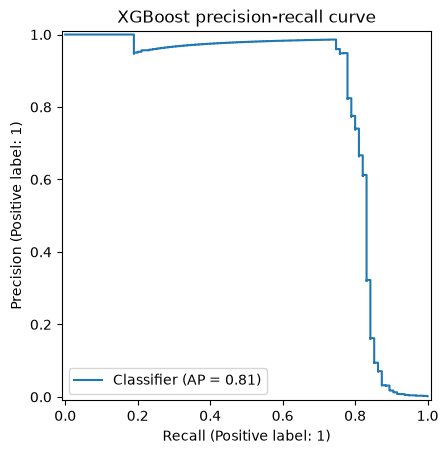

In [36]:
import os
from sklearn.metrics import PrecisionRecallDisplay
os.makedirs("outputs", exist_ok=True)

PrecisionRecallDisplay.from_predictions(y_test, proba)
plt.title("XGBoost precision-recall curve")
plt.savefig("outputs/pr_curve.png", dpi=150, bbox_inches="tight")